# ACTIVIDAD FUNDAMENTAL 6
## Ejercicio de Árbol de Decisión

<h4>IMPORTAR LOS DATOS</h4>
<p>
    En esta primer parte del ejercicio nos encargamnos de <b>implementar la fuente de datos</b> de diabetes con el URL situado mas abajo.
</p>

<p>Asimismo, podemos apreciar como tambien importamos cada una de las librerias necesarias para la ejecución de nuestro programa.</p>

<p>
    Para implementar nuestra fuente de datos utilizamos la funcion de pandas <b>pd.read_csv()</b> en la que colocamos el link junto con los nombres de las columnas para asi obtener el dataframe con todos los datos
</p>

<p>Al finalizar, unicamente mostramos los primeros 5 datos utilizando la funcion <b>df.head()</b> y describimos todas sus caracteristicas utilizando la funcion <b>df.describe()</b></p>

In [90]:
# IMPORTAR FUENTE DE DATOS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

# URL pública del dataset de Diabetes
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
columnas = [
    'Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 
    'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'
]

df = pd.read_csv(url, header=None, names=columnas)
print("Primeras filas del dataset original:")
df.head()

Primeras filas del dataset original:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


<h4>DESCRIBIR LOS DATOS</h4>
<p>
    Utilizando la funcion <b>describe()</b> mostramos conteos automaticos de nuestro dataset como por ejemplo los embarazos, glucosa, insulina, BMI (Indice de Masa Corporal), edad u otros. Aunque uno de los mas importantes es el <b>Outcome</b>, que contiene valores binarios de 0 y 1, sirviendonos para diferenciar a una persona con diabetes (1) de una sana (0).</b>
</p>

In [85]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


<h4>MOSTRAR DATOS SIN PROCESAR</h4>
<p>
    Antes de procesar los datos y limpiarlos para pasarlos por nuestro modelo, podemos mostrarlos utilizando matplotlib.
    Para ello seleccionaremos dos características principales: Glucosa (x) y BMI (y).
    Asimismo, filtramos los datos pertenecientes a a outcome 1 y 0 en ambas features seleccionadas y las mostramos con otro color (rojo, en este caso).
</p>

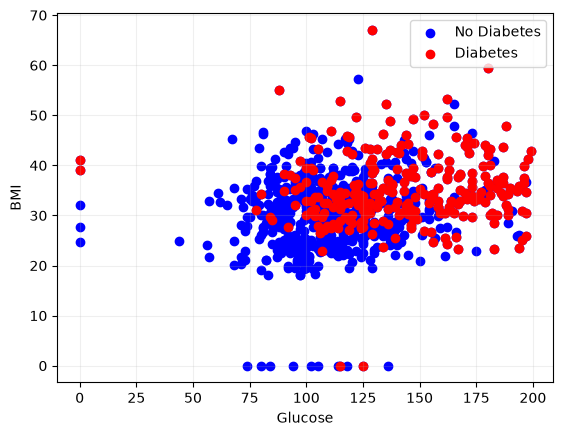

In [86]:
# MOSTRAR DATOS SIN PROCESAR

x = df['Glucose']
y = df['BMI']

x_diabetes = df[df['Outcome'] == 1]['Glucose']
y_diabetes = df[df['Outcome'] == 1]['BMI']

plt.scatter(x, y, c='blue', label = 'No Diabetes')
plt.scatter(x_diabetes, y_diabetes, c='red', label = 'Diabetes')

plt.xlabel("Glucose")
plt.ylabel("BMI")
plt.legend()
plt.grid(visible=True, alpha=0.2)

<h4>LIMPIEZA DE DATOS</h4>
<p>
    Para la limpieza de los datos, seleccionamos primero las columnas que podrían sesgar la prediccion si los datos quedan en 0.
    Reemplazamos los ceros (valores imposibles) por valores nulos y posteriormente por la mediana de cada feature.
</p>
<p>
    Posteriormente, calculamos el rango intercuartilico (IQR) para usarlo como filtro de los outliers en los datos basandonos en la insulina.
    Para obtenerlo restamos el 1er cuartil al 3ro y el resultado lo multiplicamos por 1.5.
    Despues, establecemos los limites superior e inferior usando la mediana como base e incrementandole el IQR calculado previamente.
</p>
<p>
    Al ya tener los outliers, filtramos el dataframe usandolos como base y volvemos a mostrar los datos de la misma manera que antes.
</p>


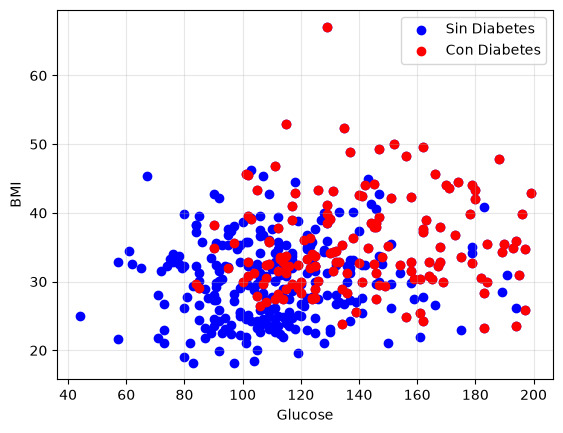

In [95]:
# LIMPIEZA DE DATOS

# Estas son las columnas cuyos valores no pueden ser cero (0)
columnasSesgadas = ['Glucose','BloodPressure','SkinThickness', 'Insulin', 'BMI']

# Reeplazar ceros por valores tipo NaN
df[columnasSesgadas] = df[columnasSesgadas].replace(0, np.nan)

# Reemplazar valores NaN por la mediana de cada columna
df[columnasSesgadas] = df[columnasSesgadas].replace(np.nan, df[columnasSesgadas].median())

# Rango Intercuartilico (IQR)
Q1 = np.percentile(df['Insulin'], 25)
Q3 = np.percentile(df['Insulin'], 75)

IQR = Q3 - Q1
rangeOutlier = IQR * 1.5

# Limites superior e inferior para outliers
limUpper = df['Insulin'].median() + rangeOutlier
limLower = df['Insulin'].median() - rangeOutlier

# Filtramos outliers
mask = (df['Insulin'] <= limUpper) & (df['Insulin'] >= limLower)
df = df[mask]

# Seleccionamos datos en X y Y
x = df['Glucose']
y = df['BMI']

# Seleccionamos datos de gente CON diabetes (Outcome = 1)
x_diabetes = df[df['Outcome'] == 1]['Glucose']
y_diabetes = df[df['Outcome'] == 1]['BMI']

# Mostramos ambos datos uno encima de otro usando scatter
plt.scatter(x, y, c='blue', label='Sin Diabetes')
plt.scatter(x_diabetes, y_diabetes, c='red', label='Con Diabetes')

plt.xlabel('Glucose')
plt.ylabel('BMI')

plt.legend()
plt.grid(visible=True, alpha=0.3)

<h4>Entrenamiento del Árbol de Decisión</h4>
<p>
    En esta ultima sección, entrenamos el arbol de decisión utilizando los datos procesados .
    Para ello, primeramos partimos en dos DF diferentes los features y los targets para poder trabajar con ellos.
    Después dividimos esos datos en los de entrenamiento y de prueba utilizando la funcion <b>train_test_split()</b> con un 25% de entrenamiento y una seed random de 42.
</p>
<p>Después creamos al modelo y lo entrenamos. Para posteriormente evaluar su accuracy y generamos el <b>reporte de clasificacion</b> utilizando una predicción generada con la parte de los datos separados para el test</p>
<p>Finalmente unicamente generamos el plot tree usando la funcion <b>plot_tree()</b></p>

              precision    recall  f1-score   support

           0       0.79      0.73      0.76        66
           1       0.56      0.64      0.60        36

    accuracy                           0.70       102
   macro avg       0.67      0.68      0.68       102
weighted avg       0.71      0.70      0.70       102



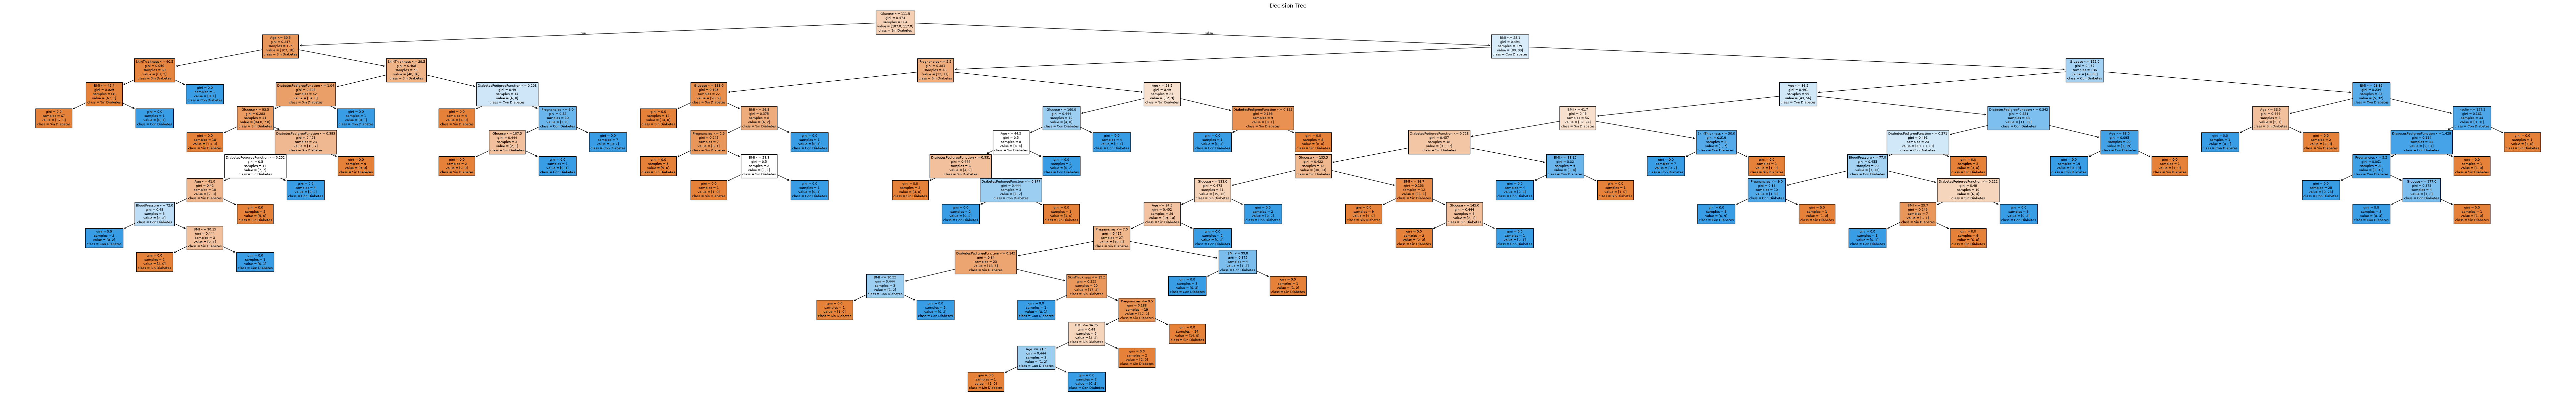

In [96]:
# ENTRENAMIENTO DE DECISION TREE

# Definimos los dataframes para los features y los targets
dfFeatures = df.drop('Outcome',axis=1)
dfTargets = df['Outcome']

# Partimos el conjunto de datos de entrenamiento y de prueba
x_train, x_test, y_train, y_test = train_test_split(dfFeatures, dfTargets, test_size = 0.25, random_state = 42)

# Creamos el modelo y lo entrenamos
model = DecisionTreeClassifier()
model.fit(x_train, y_train)

# Evaluamos el score
train_accuracy = model.score(x_train, y_train)

# Generamos una prediccion y con ella generamos un reporte de clasificacion
y_pred = model.predict(x_test)
report = classification_report(y_test, y_pred)
print(report)

# Mostramos el plot del arbol graficado.
plt.figure(figsize=(100, 15))
plot_tree(model, filled=True, feature_names = dfFeatures.columns, class_names = ['Sin Diabetes', 'Con Diabetes'])
plt.title('Decision Tree')
plt.savefig('decision_tree.png')
plt.show()
